In [35]:
import json
import os

import wandb
from evaluation.analysis_helper import get_dataframes_from_run

api = wandb.Api()

wandb_project = "learneddb/lcm"
if os.path.exists("wandb_df_cache.pkl"):
    import pickle

    with open("wandb_df_cache.pkl", "rb") as f:
        df_cache = pickle.load(f)
else:
    df_cache = dict()

In [113]:
# get last 100 runs from wandb
runs = api.runs(wandb_project, per_page=100, order="-created_at")

desc = [f"{run.name} ({run.created_at})" for run in runs]

import ipywidgets as widgets

# Create the dropdown widget
dropdown = widgets.Dropdown(
    options=desc,
    value=desc[0],  # default value
    description="Select Wandb Run:",
    disabled=False,
)

# Display the dropdown
display(dropdown)


# React to dropdown changes
def on_change(change):
    # lookup pos in runs list
    pos = desc.index(change["new"])
    run_to_analyze = runs[pos].id
    print(run_to_analyze)


dropdown.observe(on_change)

Dropdown(description='Select Wandb Run:', options=('drawn-sunset-1335 (2025-04-09T07:11:51Z)', 'zs-scanhint-en…

In [114]:
from tabulate import tabulate

tabulate_rows = []
for run in runs:
    if "accesspath_eval/total_selected_runtime" in run.summary.keys():
        tabulate_rows.append(
            [
                run.id,
                run.name,
                run.created_at,
                f"{run.summary['accesspath_eval/total_selected_runtime']:.2f}",
            ]
        )

print(
    tabulate(
        tabulate_rows,
        headers=["Run ID", "Name", "Created At", "AP Total selected runtime"],
        tablefmt="pretty",
    )
)

+----------+-------------------------------------------------------------------------------------------------------------------------------------+----------------------+---------------------------+
|  Run ID  |                                                                Name                                                                 |      Created At      | AP Total selected runtime |
+----------+-------------------------------------------------------------------------------------------------------------------------------------+----------------------+---------------------------+
| 26kf8k1k |                        zs-scanhint-enforce_aggregation_node_at_root-PostgresEstWithNumLoops-epochs100/imdb/3                        | 2025-04-09T05:13:22Z |          345.10           |
| vgh1tzsf |                                                 zs_low_min-scanhint-addfeats/imdb/3                                                 | 2025-04-08T21:40:13Z |          353.84           |
| 02trxegt

In [115]:
from analysis_helper import compute_optimal_picked_instances

# run_to_analyze = 'cf369k7y'
run_to_analyze = "khcargoh"
run_to_analyze = "26kf8k1k"
run_data = get_dataframes_from_run(run_to_analyze, df_cache, api)

df = run_data["accesspath_eval_pred_table"]
opt_runtimes, picked_runtimes, opt_plan_instances, picked_plan_instances, sqls = (
    compute_optimal_picked_instances(df)
)

print(f"Optimal runtime: {sum(opt_runtimes)}")
print(f"Picked runtime: {sum(picked_runtimes)}")

learneddb/lcm/run-26kf8k1k-accesspath_eval_pred_table:latest


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


learneddb/lcm/run-26kf8k1k-join_order_job_eval_pred_table:latest


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


learneddb/lcm/run-26kf8k1k-join_order_job_light_eval_pred_table:latest


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


learneddb/lcm/run-26kf8k1k-physop_eval_pred_table:latest


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


learneddb/lcm/run-26kf8k1k-physop_eval_with_idxs_pred_table:latest


wandb:   1 of 1 files downloaded.  
wandb:   1 of 1 files downloaded.  


Optimal runtime: 307.69997392594814
Picked runtime: 368.8416967988014


# Plot Overview

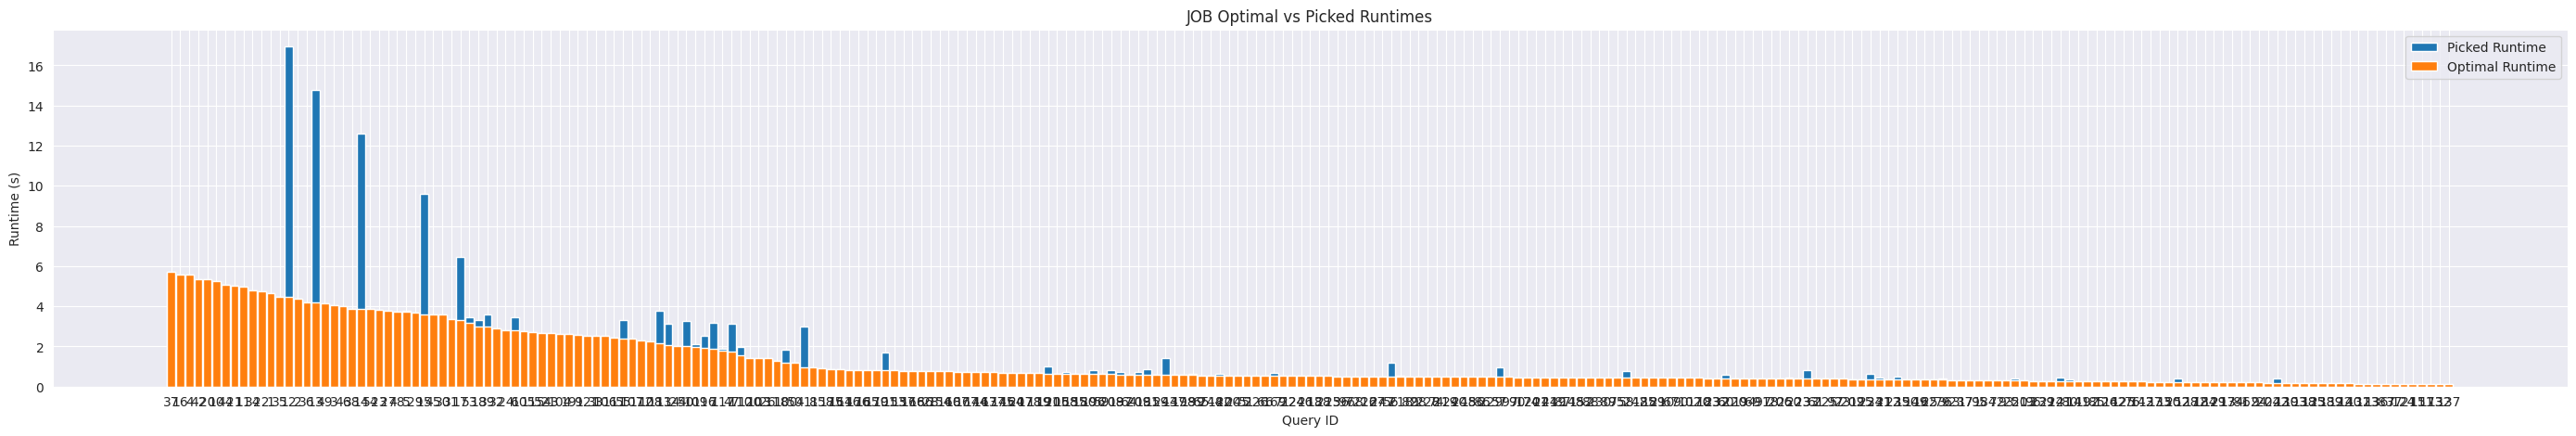

In [116]:
# plot barchart with selected runtime and optimal runtime for each query
import matplotlib.pyplot as plt

q_id = [i for i in range(len(opt_runtimes))]

# sort by opt runtime
sorted_indices = [
    i
    for i in sorted(
        range(len(opt_runtimes)), key=lambda k: opt_runtimes[k], reverse=True
    )
]
opt_runtimes_sorted = [opt_runtimes[i] for i in sorted_indices]
picked_runtimes_sorted = [picked_runtimes[i] for i in sorted_indices]
q_id_sorted = [q_id[i] + 1 for i in sorted_indices]

plt.figure(figsize=(35, 5))
bar_width = 0.9
indices = range(len(opt_runtimes))
plt.bar(indices, picked_runtimes_sorted, width=bar_width, label="Picked Runtime")
plt.bar(indices, opt_runtimes_sorted, width=bar_width, label="Optimal Runtime")
plt.xticks([i for i in indices], q_id_sorted)
plt.legend()
plt.xlabel("Query ID")
plt.ylabel("Runtime (s)")
plt.title("JOB Optimal vs Picked Runtimes")
plt.show()

In [117]:
# min / max / mean / median label / pred
from tabulate import tabulate

tabulate_rows = []
tabulate_rows.append(
    [
        "Label",
        df["label"].min(),
        df["label"].max(),
        df["label"].mean(),
        df["label"].median(),
    ]
)
tabulate_rows.append(
    [
        "Prediction",
        df["prediction"].min(),
        df["prediction"].max(),
        df["prediction"].mean(),
        df["prediction"].median(),
    ]
)
print(tabulate(tabulate_rows, headers=["Type", "Min", "Max", "Mean", "Median"]))

Type             Min      Max     Mean    Median
----------  --------  -------  -------  --------
Label       0.103877  26.2273  1.75729  0.641834
Prediction  0.100873  29.395   2.5711   0.990444


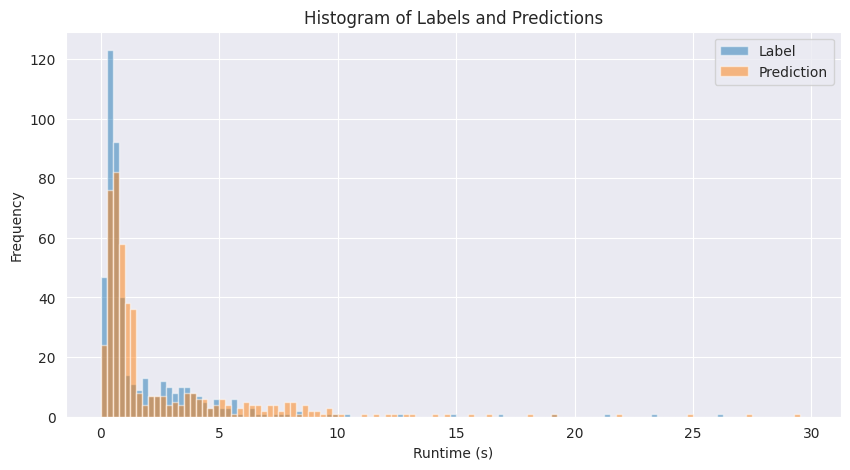

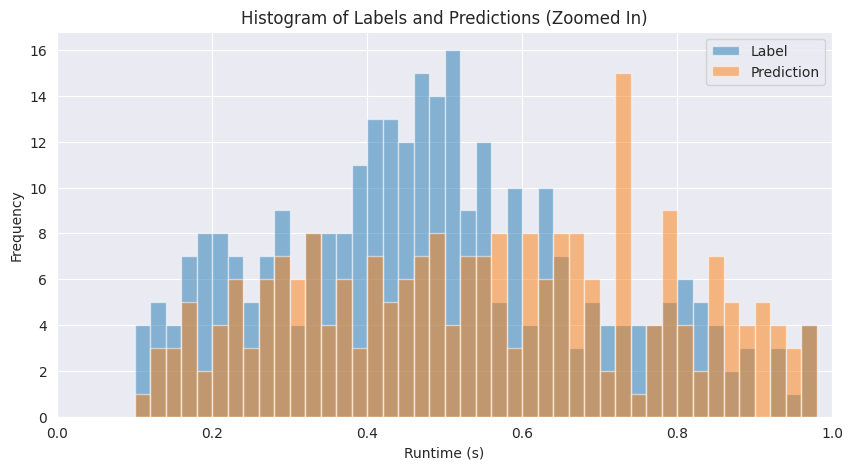

In [118]:
# create equal width bins between 0 and 30s
import numpy as np

bins = np.arange(0, 30, 0.25)

# plot histogram of labels and predictions
plt.figure(figsize=(10, 5))
plt.hist(df["label"], bins=bins, alpha=0.5, label="Label")
plt.hist(df["prediction"], bins=bins, alpha=0.5, label="Prediction")
plt.xlabel("Runtime (s)")
plt.ylabel("Frequency")
plt.legend()
plt.title("Histogram of Labels and Predictions")
plt.show()

# plot a zoomed in version 0-1s
bins = np.arange(0, 1, 0.02)
plt.figure(figsize=(10, 5))
plt.hist(df["label"], bins=bins, alpha=0.5, label="Label")
plt.hist(df["prediction"], bins=bins, alpha=0.5, label="Prediction")
plt.xlim(0, 1)
plt.xlabel("Runtime (s)")
plt.ylabel("Frequency")
plt.legend()
plt.title("Histogram of Labels and Predictions (Zoomed In)")
plt.show()

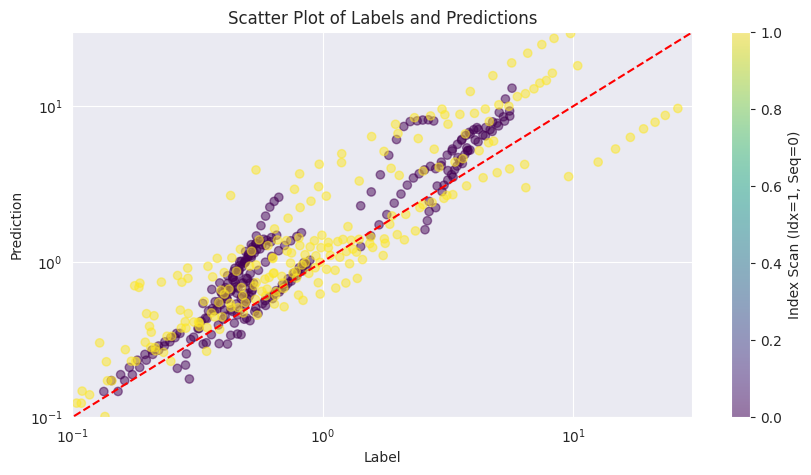

In [119]:
# create scatter plot of labels & predictions
plt.figure(figsize=(10, 5))

is_idx_scan = df["scan_op"] == "Index Scan"

plt.scatter(df["label"], df["prediction"], alpha=0.5, c=is_idx_scan, cmap="viridis")
plt.colorbar(label="Index Scan (Idx=1, Seq=0)")
# plt.scatter(df['label'], df['prediction'], alpha=0.5)
plt.xlabel("Label")
plt.ylabel("Prediction")
plt.title("Scatter Plot of Labels and Predictions")
plt.xscale("log")
plt.yscale("log")
plt.xlim(0.1, 30)
plt.ylim(0.1, 30)
plt.plot([0.001, 30], [0.001, 30], color="red", linestyle="--")
plt.show()

In [120]:
# counter number of labels >25ms and <25ms
print(f"Number of labels > 25ms: {len(df[df['label'] > 0.1])}")
print(f"Number of labels < 25ms: {len(df[df['label'] <= 0.1])}")

Number of labels > 25ms: 475
Number of labels < 25ms: 0


In [121]:
from ldb_schema.load_schema import load_json
from ldb_schema.paths import LocalPaths

# plot distribution of scan-only workload
scan_only_path = (
    LocalPaths().Data.parsed_plans2.as_posix()
    + "/imdb_scaled1/scan_only_s1_access_path_hints.json"
)
run = load_json(str(scan_only_path))
plans = run["parsed_plans"]
plans = [
    p
    for p in plans
    if not p["invalid_hint"] and not p["zero_card"] and not p["timeout"]
]

runtimes = [p["plan_runtime_ms"] for p in plans]

# print avg / min / max /median of runtimes
print(f"Avg runtime: {sum(runtimes) / len(runtimes)}")
print(f"Min runtime: {min(runtimes)}")
print(f"Max runtime: {max(runtimes)}")
print(f"Median runtime: {sorted(runtimes)[len(runtimes) // 2]}")

Avg runtime: 990.1268238295319
Min runtime: 25.025
Max runtime: 29504.43
Median runtime: 443.555


# Plot worst prediction

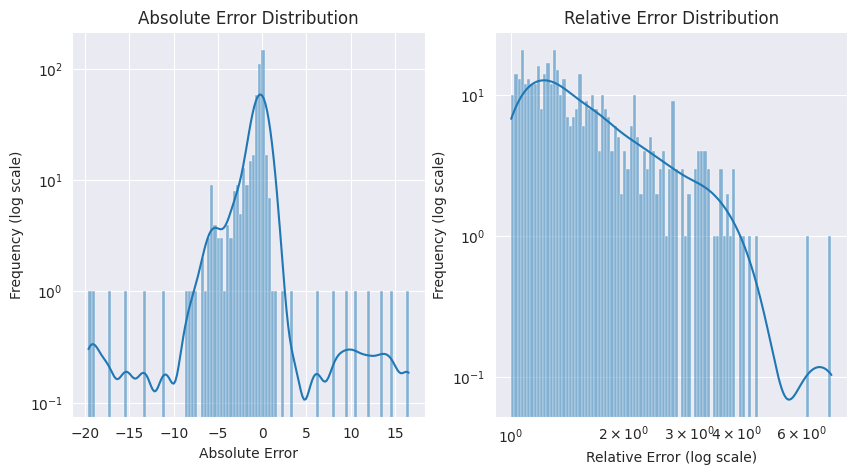

In [122]:
import numpy as np
from ldb_schema.paths import LocalPaths
from analysis_helper import find_plan_by_sql

df["qerror"] = np.maximum(
    df["label"] / df["prediction"], df["prediction"] / df["label"]
)
df["abserror"] = np.abs(df["label"] - df["prediction"])

df["abserror_signed"] = df["label"] - df["prediction"]


def print_error_info(relative: bool = True):
    # print info of worst entry
    worst_entry = df.loc[df["qerror" if relative else "abserror"].idxmax()]
    print(worst_entry)

    ap_filepath = (
        LocalPaths().Data.parsed_plans2.as_posix()
        + "/imdb_scaled1/access_path_selection.json"
    )

    # lookup plan
    matching_plans = find_plan_by_sql(
        worst_entry["sql"], worst_entry["hint"], ap_filepath
    )
    assert len(matching_plans) == 1

    print(json.dumps(matching_plans[0], indent=2))


# plot abs error / q-error distribution (multiplot)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.histplot(df["abserror_signed"], bins=100, kde=True)
plt.xlabel("Absolute Error")
plt.ylabel("Frequency (log scale)")
plt.yscale("log")
plt.title("Absolute Error Distribution")
plt.subplot(1, 2, 2)
plt.xlabel("Relative Error (log scale)")
plt.xscale("log")
plt.ylabel("Frequency (log scale)")
plt.yscale("log")
plt.title("Relative Error Distribution")
sns.histplot(df["qerror"], bins=100, kde=True)
plt.show()

In [123]:
print_error_info(relative=True)

query_index                                                             302
label                                                              0.541172
prediction                                                         3.892396
sql                SELECT * FROM cast_info WHERE person_role_id >= 2545920;
hint                 /*+IndexScan(cast_info idx_cast_info_person_role_id)*/
selectivity                                                        0.048481
scan_op                                                          Index Scan
join_op                                                                None
qerror                                                              7.19253
abserror                                                           3.351224
abserror_signed                                                   -3.351224
Name: 302, dtype: object
{
  "plan_parameters": {
    "act_card": 1757153,
    "act_time": 440.93,
    "act_loops": 1,
    "est_card": 1775618,
    "est_width": 42,

In [124]:
print_error_info(relative=False)

query_index                                                      263
label                                                       9.772341
prediction                                                 29.394955
sql                    SELECT * FROM cast_info WHERE person_id >= 1;
hint               /*+IndexScan(cast_info idx_cast_info_person_id)*/
selectivity                                                      1.0
scan_op                                                   Index Scan
join_op                                                         None
qerror                                                      3.007975
abserror                                                   19.622614
abserror_signed                                           -19.622614
Name: 263, dtype: object
{
  "plan_parameters": {
    "act_card": 36244344,
    "act_time": 8218.848,
    "act_loops": 1,
    "est_card": 36244344,
    "est_width": 42,
    "pg_cost": 1439049.18,
    "est_loops": 1,
    "table_name": "cast_i